<a href="https://colab.research.google.com/github/Visweash1234/Applied-Data-Science-1/blob/main/ADS1_Tutorial_5_Distributions_Practice.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
#Setup the necessary Libraries.
#We added in a new library scipy
import numpy as np
import pandas as pd
import scipy.stats as ss
import matplotlib.pyplot as plt
from scipy import stats
import math

np.random.seed(42)

plt.rcParams.update({"figure.figsize": (6,4)})

def ecdf(x):
    x = np.sort(np.asarray(x))
    y = np.arange(1, len(x)+1) / len(x)
    return x, y

def describe_four_moments(x):
    x = np.asarray(x)
    mean = np.mean(x)
    var = np.var(x, ddof=0)
    std = np.sqrt(var)
    skew = stats.skew(x, bias=False)
    kurt = stats.kurtosis(x, fisher=False, bias=False)
    return {"mean": mean, "variance": var, "std": std, "skewness": skew, "kurtosis": kurt}


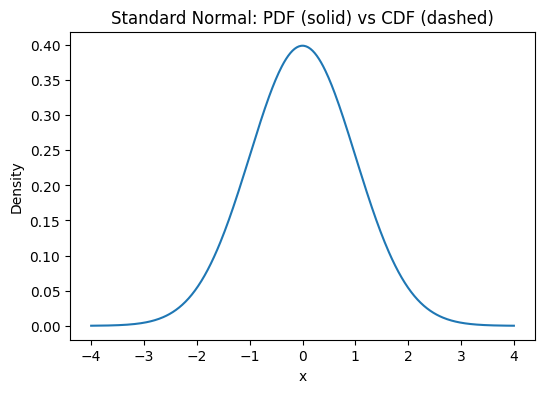

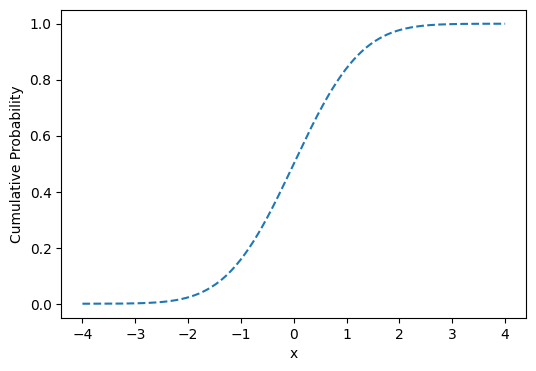

Phi(1) via erf: 0.8413447460685429
Phi(1) via scipy: 0.8413447460685429


In [2]:
x = np.linspace(-4, 4, 400)
pdf = stats.norm.pdf(x, loc=0, scale=1)
cdf = stats.norm.cdf(x, loc=0, scale=1)
plt.plot(x, pdf, label="PDF")
plt.xlabel("x"); plt.ylabel("Density")
plt.title("Standard Normal: PDF (solid) vs CDF (dashed)")
plt.show()
plt.plot(x, cdf, linestyle="--", label="CDF")
plt.xlabel("x"); plt.ylabel("Cumulative Probability")
plt.show()

phi_1 = 0.5*(1 + math.erf(1/np.sqrt(2)))
print("Phi(1) via erf:", phi_1)
print("Phi(1) via scipy:", stats.norm.cdf(1.0))


Empirical moments (Normal): {'mean': np.float64(1.9967960249473606), 'variance': np.float64(2.2653811246739597), 'std': np.float64(1.5051183091949814), 'skewness': np.float64(0.0019639923774888964), 'kurtosis': np.float64(3.027092756848509)}
Theoretical moments (Normal): {'mean': 2.0, 'variance': 2.25, 'std': 1.5, 'skewness': 0.0, 'kurtosis': 3.0}


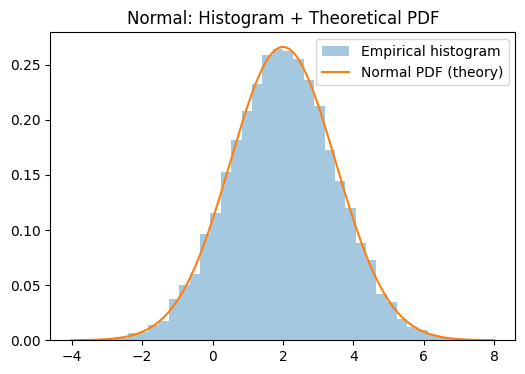

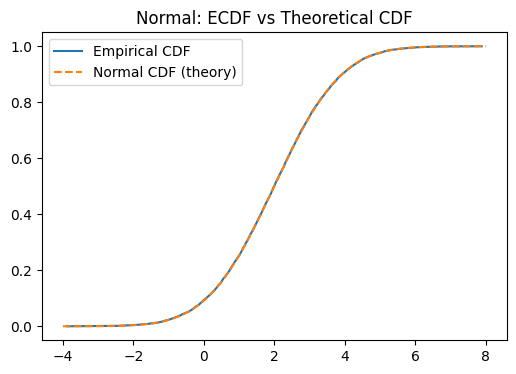

In [3]:
mu, sigma = 2.0, 1.5
n = 10_000
x_norm = np.random.normal(loc=mu, scale=sigma, size=n)
m = describe_four_moments(x_norm)
print("Empirical moments (Normal):", m)
theory = {"mean": mu, "variance": sigma**2, "std": sigma, "skewness": 0.0, "kurtosis": 3.0}
print("Theoretical moments (Normal):", theory)
xx = np.linspace(mu - 4*sigma, mu + 4*sigma, 400)
plt.hist(x_norm, bins=40, density=True, alpha=0.4, label="Empirical histogram")
plt.plot(xx, stats.norm.pdf(xx, mu, sigma), label="Normal PDF (theory)")
plt.title("Normal: Histogram + Theoretical PDF")
plt.legend(); plt.show()
xs, ys = ecdf(x_norm)
plt.plot(xs, ys, label="Empirical CDF")
plt.plot(xx, stats.norm.cdf(xx, mu, sigma), linestyle="--", label="Normal CDF (theory)")
plt.title("Normal: ECDF vs Theoretical CDF")
plt.legend(); plt.show()


## 1) Normal Distribution

Large-n empirical moments: {'mean': np.float64(1.9813058466539766), 'variance': np.float64(2.2113262817983492), 'std': np.float64(1.4870528846676399), 'skewness': np.float64(0.007715402864270242), 'kurtosis': np.float64(2.9143104868957614)}
Phi(1.5) via erf: 0.9331927987311419  | via scipy: 0.9331927987311419
With outliers: {'mean': np.float64(1.9888058466539766), 'variance': np.float64(2.3185811060311683), 'std': np.float64(1.5226887751708056), 'skewness': np.float64(0.44772686285308655), 'kurtosis': np.float64(7.10797982577766)}


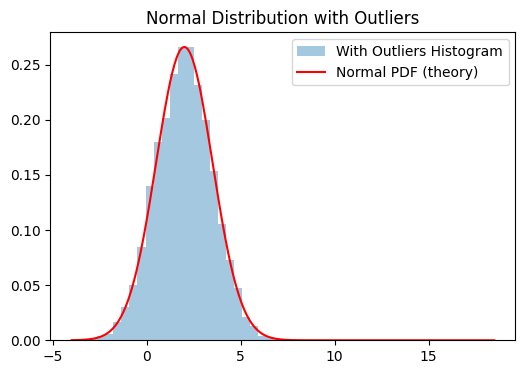

In [5]:
# Set mu_s and sigma_s
mu_s, sigma_s = 2.0, 1.5
n_s = 10_000

#Generate a random normal distribution
x_s = np.random.normal(loc=mu_s, scale=sigma_s, size=n_s)

#use the above function created above to find the 4 moments
sol = describe_four_moments(x_s)

#Print out the moments
print("Large-n empirical moments:", sol)

# Calculate the error function using the formula
phi_15_erf = 0.5 * (1 + math.erf(1.5 / np.sqrt(2)))

#Calculate the error using stats.norm.cdf(1.5)
phi_15_sci = stats.norm.cdf(1.5)

# Print out both results
print("Phi(1.5) via erf:", phi_15_erf, " | via scipy:", phi_15_sci)

#Copy the distribution to another distrbution named x_out
x_out = np.copy(x_s)

#Add in 5 outliers randomly
x_out[:5] = x_out[:5] + 10*sigma_s
print("With outliers:", describe_four_moments(x_out))

# Try to plot out the resulting histrogram
plt.hist(x_out, bins=50, density=True, alpha=0.4, label="With Outliers Histogram")
xx = np.linspace(mu_s - 4*sigma_s, mu_s + 11*sigma_s, 400)
plt.plot(xx, stats.norm.pdf(xx, mu_s, sigma_s), 'r-', label="Normal PDF (theory)")
plt.title("Normal Distribution with Outliers")
plt.legend()
plt.show()

## 2) Uniform Distribution


Empirical moments (Uniform): {'mean': np.float64(0.9915100629378838), 'variance': np.float64(5.395113638414467), 'std': np.float64(2.3227383921600957), 'skewness': np.float64(0.011193502584215328), 'kurtosis': np.float64(1.7813559805235653)}
Theoretical moments (Uniform): {'mean': 1.0, 'variance': 5.333333333333333, 'std': np.float64(2.309401076758503), 'skewness': 0.0, 'kurtosis': 1.8}


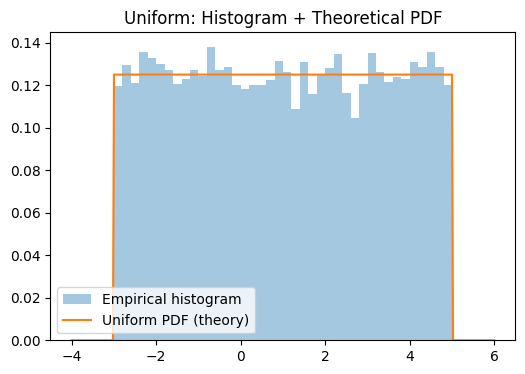

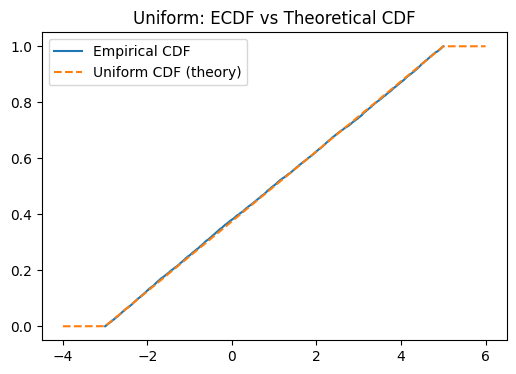

In [6]:
a, b = -3.0, 5.0
n = 10_000
x_uni = np.random.uniform(a, b, size=n)
m = describe_four_moments(x_uni)
print("Empirical moments (Uniform):", m)
theory = {"mean": 0.5*(a+b), "variance": (b-a)**2/12, "std": np.sqrt((b-a)**2/12), "skewness": 0.0, "kurtosis": 1.8}
print("Theoretical moments (Uniform):", theory)
xx = np.linspace(a-1, b+1, 400)
pdf_uni = np.where((xx>=a)&(xx<=b), 1.0/(b-a), 0.0)
plt.hist(x_uni, bins=40, density=True, alpha=0.4, label="Empirical histogram")
plt.plot(xx, pdf_uni, label="Uniform PDF (theory)")
plt.title("Uniform: Histogram + Theoretical PDF")
plt.legend(); plt.show()
xs, ys = ecdf(x_uni)
plt.plot(xs, ys, label="Empirical CDF")
cdf_uni = np.piecewise(xx, [xx<a, (xx>=a)&(xx<=b), xx>b], [0.0, lambda z: (z-a)/(b-a), 1.0])
plt.plot(xx, cdf_uni, linestyle="--", label="Uniform CDF (theory)")
plt.title("Uniform: ECDF vs Theoretical CDF")
plt.legend(); plt.show()

In [7]:
# Define the interval limits for the Uniform distribution
a_u, b_u = -3.0, 5.0
n_u = 10_000

# Generate random uniform samples
x_uni_sample = np.random.uniform(low=a_u, high=b_u, size=n_u)

# Calculate empirical moments
empirical_uni_moments = describe_four_moments(x_uni_sample)
print("Empirical Uniform Moments:", empirical_uni_moments)

# Theoretical moments calculations
theoretical_mean = 0.5 * (a_u + b_u)
theoretical_var = ((b_u - a_u) ** 2) / 12.0
theoretical_std = np.sqrt(theoretical_var)
theoretical_skew = 0.0
theoretical_kurt = 1.8  # Fisher-unbiased kurtosis + 3 (as our function has fisher=False)

theory_uni_moments = {
    "mean": theoretical_mean,
    "variance": theoretical_var,
    "std": theoretical_std,
    "skewness": theoretical_skew,
    "kurtosis": theoretical_kurt
}
print("Theoretical Uniform Moments:", theory_uni_moments)

Empirical Uniform Moments: {'mean': np.float64(1.0085867938847106), 'variance': np.float64(5.28785348019126), 'std': np.float64(2.2995333179128457), 'skewness': np.float64(-0.017944720253319807), 'kurtosis': np.float64(1.8117213720631034)}
Theoretical Uniform Moments: {'mean': 1.0, 'variance': 5.333333333333333, 'std': np.float64(2.309401076758503), 'skewness': 0.0, 'kurtosis': 1.8}


## 3) Lognormal Distribution

Empirical moments (Lognormal): {'mean': np.float64(1.6171576283253568), 'variance': np.float64(1.1093936996928058), 'std': np.float64(1.0532775985906118), 'skewness': np.float64(1.9947144659366254), 'kurtosis': np.float64(9.87008261258612)}
Selected theoretical moments (Lognormal): {'mean': np.float64(1.6160744021928934), 'variance': np.float64(1.1317249038377446), 'std': np.float64(1.0638255984125145)}


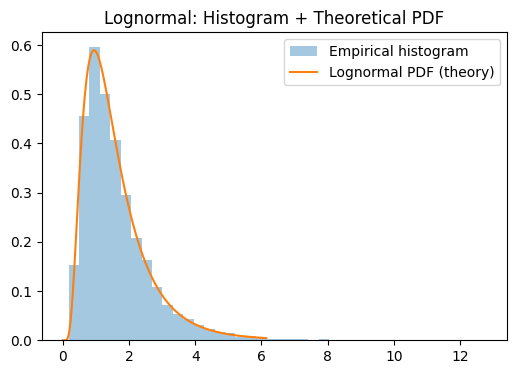

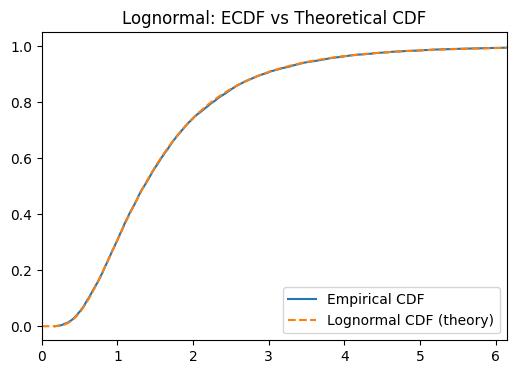

In [8]:
mu_log, sigma_log = 0.3, 0.6
n = 10_000
x_logn = np.random.lognormal(mean=mu_log, sigma=sigma_log, size=n)
m = describe_four_moments(x_logn)
print("Empirical moments (Lognormal):", m)
theory = {"mean": np.exp(mu_log + sigma_log**2/2),
          "variance": (np.exp(sigma_log**2)-1)*np.exp(2*mu_log + sigma_log**2)}
theory["std"] = np.sqrt(theory["variance"])
print("Selected theoretical moments (Lognormal):", theory)
xx = np.linspace(0, np.percentile(x_logn, 99.5), 400)
plt.hist(x_logn, bins=40, density=True, alpha=0.4, label="Empirical histogram")
plt.plot(xx, stats.lognorm.pdf(xx, s=sigma_log, scale=np.exp(mu_log)), label="Lognormal PDF (theory)")
plt.title("Lognormal: Histogram + Theoretical PDF")
plt.legend(); plt.show()
xs, ys = ecdf(x_logn)
plt.plot(xs, ys, label="Empirical CDF")
plt.plot(xx, stats.lognorm.cdf(xx, s=sigma_log, scale=np.exp(mu_log)), linestyle="--", label="Lognormal CDF (theory)")
plt.xlim(0, np.percentile(x_logn, 99.5))
plt.title("Lognormal: ECDF vs Theoretical CDF")
plt.legend(); plt.show()


In [9]:
# Calculate empirical moments for lognormal distribution
empirical_lognorm_moments = describe_four_moments(x_logn)
print("Empirical Lognormal Moments:", empirical_lognorm_moments)

# Theoretical moments calculations for Lognormal distribution
# variance_parameter (s^2) is sigma_log^2
omega = np.exp(sigma_log**2)

theoretical_mean = np.exp(mu_log + (sigma_log**2) / 2.0)
theoretical_var = (omega - 1.0) * np.exp(2.0 * mu_log + sigma_log**2)
theoretical_std = np.sqrt(theoretical_var)
theoretical_skew = (omega + 2.0) * np.sqrt(omega - 1.0)
theoretical_kurt = omega**4 + 2.0*omega**3 + 3.0*omega**2 - 3.0

theory_lognorm_moments = {
    "mean": theoretical_mean,
    "variance": theoretical_var,
    "std": theoretical_std,
    "skewness": theoretical_skew,
    "kurtosis": theoretical_kurt
}
print("Theoretical Lognormal Moments:", theory_lognorm_moments)

Empirical Lognormal Moments: {'mean': np.float64(1.6171576283253568), 'variance': np.float64(1.1093936996928058), 'std': np.float64(1.0532775985906118), 'skewness': np.float64(1.9947144659366254), 'kurtosis': np.float64(9.87008261258612)}
Theoretical Lognormal Moments: {'mean': np.float64(1.6160744021928934), 'variance': np.float64(1.1317249038377446), 'std': np.float64(1.0638255984125145), 'skewness': np.float64(2.2600838884867054), 'kurtosis': np.float64(13.273354551059256)}


## 4) Binomial Distribution


Empirical moments (Binomial): {'mean': np.float64(6.9966), 'variance': np.float64(4.38838844), 'std': np.float64(2.094848070863374), 'skewness': np.float64(0.11925652294924163), 'kurtosis': np.float64(2.9709428092185717)}
Selected theoretical moments (Binomial): {'mean': 7.0, 'variance': 4.55, 'std': np.float64(2.1330729007701543)}


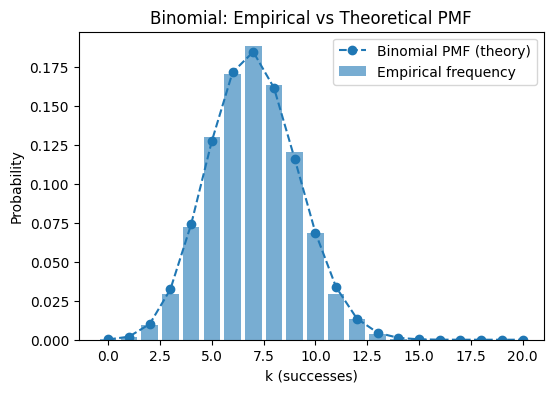

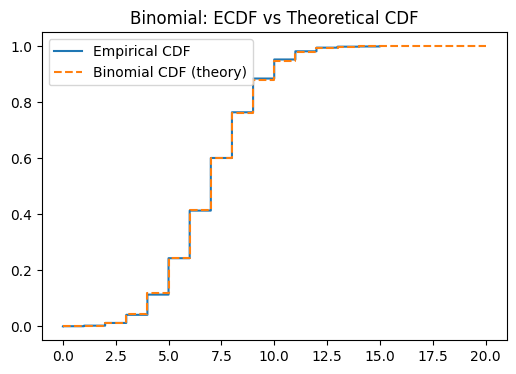

In [10]:
n_trials, p = 20, 0.35
n = 10_000
x_bin = np.random.binomial(n=n_trials, p=p, size=n)
m = describe_four_moments(x_bin)
print("Empirical moments (Binomial):", m)
theory = {"mean": n_trials*p, "variance": n_trials*p*(1-p)}
theory["std"] = np.sqrt(theory["variance"])
print("Selected theoretical moments (Binomial):", theory)
vals, counts = np.unique(x_bin, return_counts=True)
plt.bar(vals, counts/np.sum(counts), alpha=0.6, label="Empirical frequency")
k = np.arange(0, n_trials+1)
plt.plot(k, stats.binom.pmf(k, n_trials, p), marker="o", linestyle="--", label="Binomial PMF (theory)")
plt.xlabel("k (successes)"); plt.ylabel("Probability")
plt.title("Binomial: Empirical vs Theoretical PMF")
plt.legend(); plt.show()
xs, ys = ecdf(x_bin)
plt.step(xs, ys, where="post", label="Empirical CDF")
plt.step(k, stats.binom.cdf(k, n_trials, p), where="post", linestyle="--", label="Binomial CDF (theory)")
plt.title("Binomial: ECDF vs Theoretical CDF")
plt.legend(); plt.show()


In [11]:
# Calculate empirical moments for Binomial distribution
empirical_binomial_moments = describe_four_moments(x_bin)
print("Empirical Binomial Moments:", empirical_binomial_moments)

# Theoretical skewness and kurtosis for Binomial(n, p)
# Skewness = (1 - 2p) / sqrt(n * p * (1 - p))
# Kurtosis (Fisher-unbiased + 3) = 3 + (1 - 6p(1-p)) / (n * p * (1-p))
theoretical_mean = n_trials * p
theoretical_var = n_trials * p * (1.0 - p)
theoretical_std = np.sqrt(theoretical_var)
theoretical_skew = (1.0 - 2.0 * p) / theoretical_std
theoretical_kurt = 3.0 + (1.0 - 6.0 * p * (1.0 - p)) / theoretical_var

theory_binomial_moments = {
    "mean": theoretical_mean,
    "variance": theoretical_var,
    "std": theoretical_std,
    "skewness": theoretical_skew,
    "kurtosis": theoretical_kurt
}
print("Theoretical Binomial Moments:", theory_binomial_moments)

Empirical Binomial Moments: {'mean': np.float64(6.9966), 'variance': np.float64(4.38838844), 'std': np.float64(2.094848070863374), 'skewness': np.float64(0.11925652294924163), 'kurtosis': np.float64(2.9709428092185717)}
Theoretical Binomial Moments: {'mean': 7.0, 'variance': 4.55, 'std': np.float64(2.1330729007701543), 'skewness': np.float64(0.14064216928154863), 'kurtosis': 2.9197802197802196}


## 5) Error Function (`erf`) Practice


In [12]:
xs = np.array([-2, -1, 0, 1, 2], dtype=float)
phi_erf = 0.5*(1 + np.array([math.erf(x/np.sqrt(2)) for x in xs]))
phi_sci = stats.norm.cdf(xs)
for x, a, b in zip(xs, phi_erf, phi_sci):
    print(f"x={x:>4}: Phi via erf={a:.6f} | via scipy={b:.6f} | diff={abs(a-b):.2e}")


x=-2.0: Phi via erf=0.022750 | via scipy=0.022750 | diff=1.39e-17
x=-1.0: Phi via erf=0.158655 | via scipy=0.158655 | diff=0.00e+00
x= 0.0: Phi via erf=0.500000 | via scipy=0.500000 | diff=0.00e+00
x= 1.0: Phi via erf=0.841345 | via scipy=0.841345 | diff=0.00e+00
x= 2.0: Phi via erf=0.977250 | via scipy=0.977250 | diff=0.00e+00


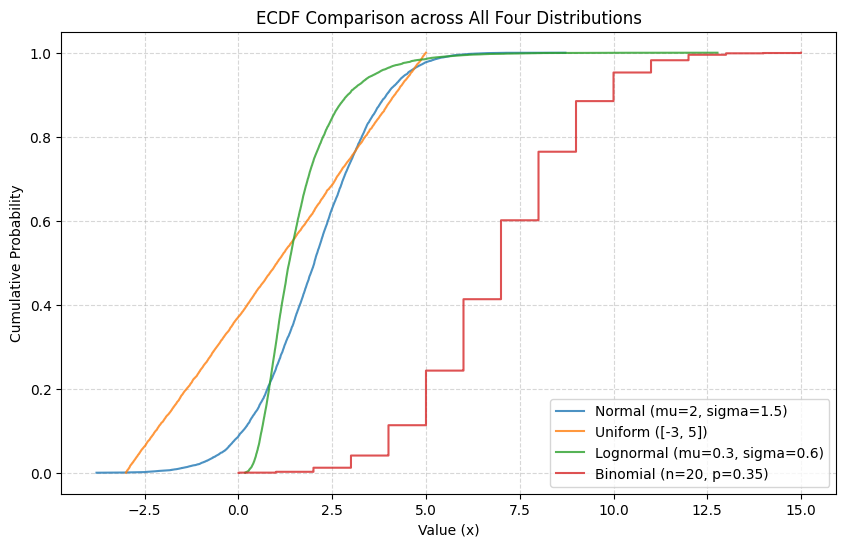

In [13]:
plt.figure(figsize=(10, 6))

# Calculate and plot ECDF for each distribution
for dist_name, data in [
    ("Normal (mu=2, sigma=1.5)", x_norm),
    ("Uniform ([-3, 5])", x_uni_sample),
    ("Lognormal (mu=0.3, sigma=0.6)", x_logn),
    ("Binomial (n=20, p=0.35)", x_bin)
]:
    xs_ecdf, ys_ecdf = ecdf(data)
    if "Binomial" in dist_name:
        plt.step(xs_ecdf, ys_ecdf, where="post", label=dist_name, alpha=0.8)
    else:
        plt.plot(xs_ecdf, ys_ecdf, label=dist_name, alpha=0.8)

plt.title("ECDF Comparison across All Four Distributions")
plt.xlabel("Value (x)")
plt.ylabel("Cumulative Probability")
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend()
plt.show()

# Practice Question



In [15]:
df_dists = pd.read_csv('/content/distributions.csv')
display(df_dists.describe())
display(df_dists.head())

,Normal,Dist1,Dist2,Dist3
count,9999.000000,9999.000000,9999.000000,9999.000000
mean,0.018063,2.004508,0.076369,-0.798484
std,1.001708,1.283716,2.874266,1.278739
min,-3.550027,-5.101586,-4.999607,-3.901247
25%,-0.644866,1.437169,-2.398181,-1.689101
50%,0.003320,2.002493,0.105046,-0.997653
75%,0.701411,2.564804,2.557288,-0.161064
max,4.028232,8.716603,4.998277,11.220154


,Normal,Dist1,Dist2,Dist3
0,0.337123,2.607079,-3.486553,-0.676021
1,-1.700663,1.552647,4.670151,0.535188
2,-1.470421,2.142991,0.986844,-1.898905
3,-1.349838,2.416067,4.484968,-2.677369
4,-0.344542,2.030476,-3.174234,-2.006907


In [16]:
for col in df_dists.columns:
    moments = describe_four_moments(df_dists[col])
    print(f"Column '{col}' empirical moments:")
    for k, v in moments.items():
        print(f"  {k:<10}: {v:.6f}")
    print()

Column 'Normal' empirical moments:
  mean      : 0.018063
  variance  : 1.003319
  std       : 1.001658
  skewness  : 0.023976
  kurtosis  : 3.000977

Column 'Dist1' empirical moments:
  mean      : 2.004508
  variance  : 1.647761
  std       : 1.283651
  skewness  : -0.024262
  kurtosis  : 5.798743

Column 'Dist2' empirical moments:
  mean      : 0.076369
  variance  : 8.260580
  std       : 2.874122
  skewness  : -0.037357
  kurtosis  : 1.814286

Column 'Dist3' empirical moments:
  mean      : -0.798484
  variance  : 1.635010
  std       : 1.278675
  skewness  : 1.228820
  kurtosis  : 6.175012



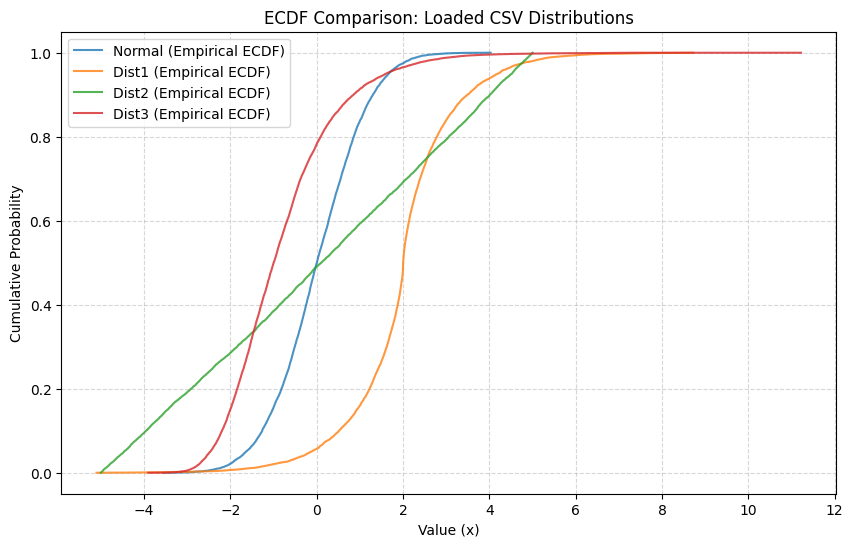

In [17]:
plt.figure(figsize=(10, 6))
for col in df_dists.columns:
    xs_ecdf, ys_ecdf = ecdf(df_dists[col])
    plt.plot(xs_ecdf, ys_ecdf, label=f"{col} (Empirical ECDF)", alpha=0.8)

plt.title("ECDF Comparison: Loaded CSV Distributions")
plt.xlabel("Value (x)")
plt.ylabel("Cumulative Probability")
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend()
plt.show()

In [18]:
def plot_file_distributions():
    """
    Key in the codes to Plot the four distributions from the file
    """
    fig, axs = plt.subplots(2, 2, dpi=144)
    axs = axs.flatten()

    for i, dist in enumerate(df_dists.columns):
        axs[i].hist(df_dists[dist], range=(-6, 12), bins=18)
        axs[i].set_title(dist)

    fig.subplots_adjust(hspace=0.5)
    fig.supxlabel('x')
    fig.supylabel('N')
    plt.show()
    return

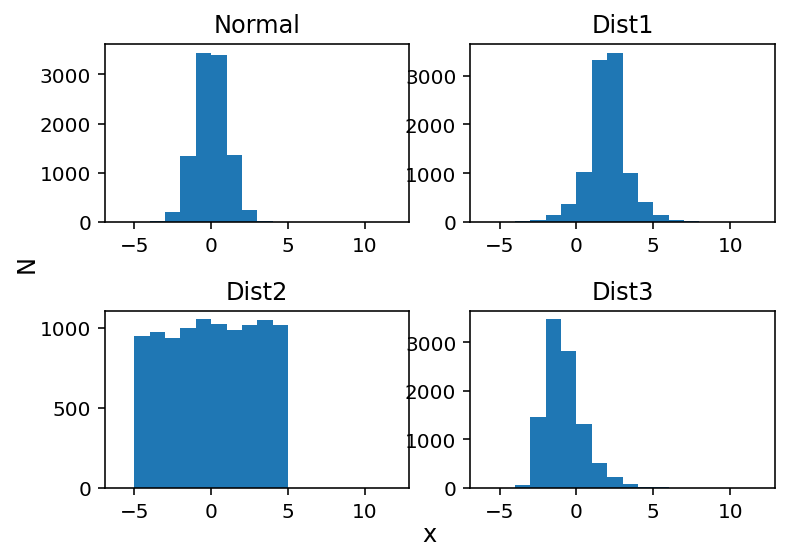

In [19]:
plot_file_distributions()

In [23]:
# Calculate moments for each distribution from the CSV file and summarize them in a table
moments_list = []
for col in df_dists.columns:
    moments = describe_four_moments(df_dists[col])
    moments['Distribution'] = col
    moments_list.append(moments)

# Create a DataFrame and reorder columns for display
df_moments = pd.DataFrame(moments_list)
df_moments = df_moments[['Distribution', 'mean', 'variance', 'std', 'skewness', 'kurtosis']]
display(df_moments.round(6))

,Distribution,mean,variance,std,skewness,kurtosis
0,Normal,0.018063,1.003319,1.001658,0.023976,3.000977
1,Dist1,2.004508,1.647761,1.283651,-0.024262,5.798743
2,Dist2,0.076369,8.260580,2.874122,-0.037357,1.814286
3,Dist3,-0.798484,1.635010,1.278675,1.228820,6.175012


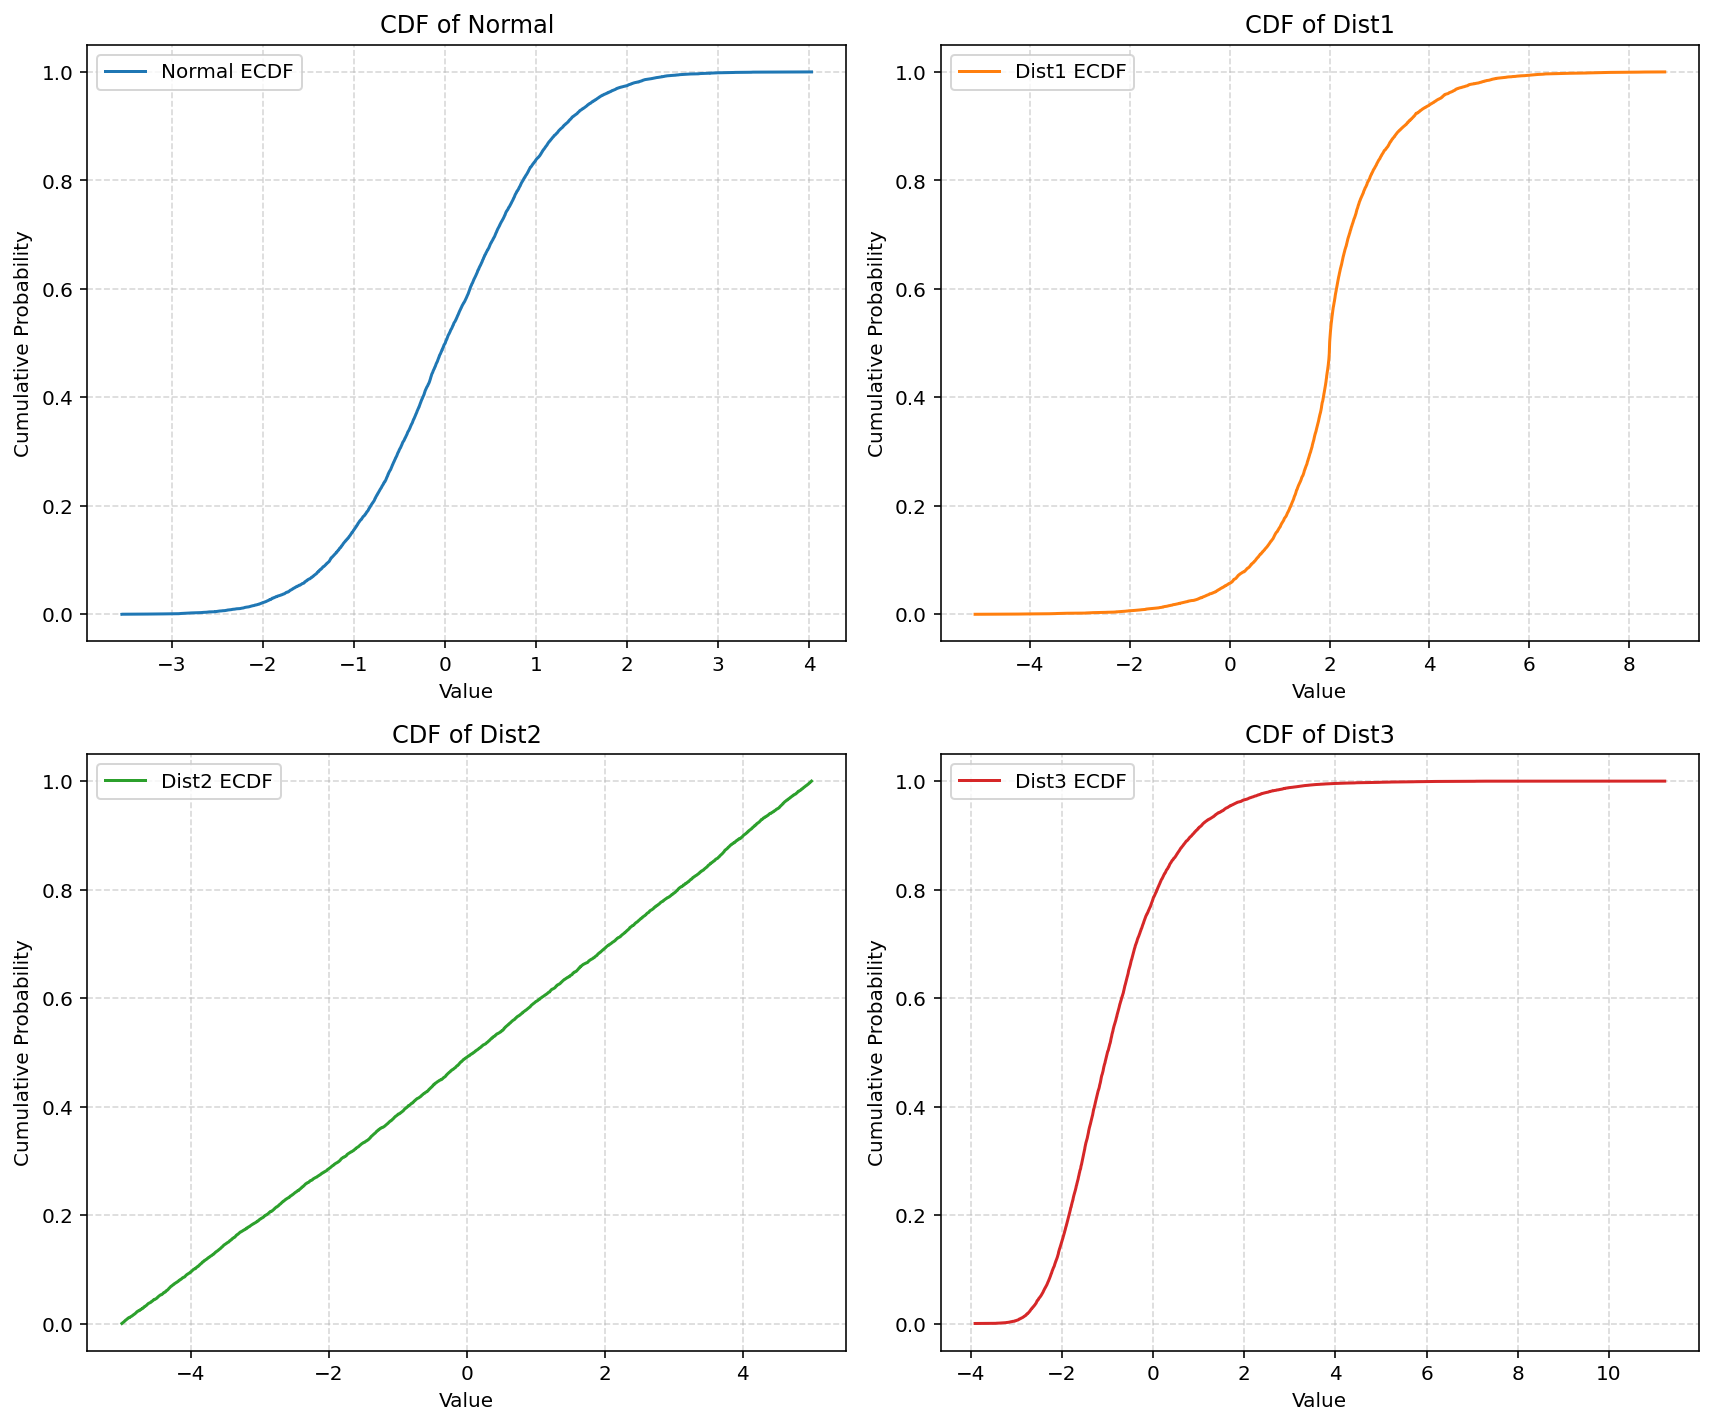

In [25]:
# Plot the CDF for each distribution in a 2x2 subplot layout
fig, axs = plt.subplots(2, 2, figsize=(12, 10), dpi=144)
axs = axs.flatten()

for i, col in enumerate(df_dists.columns):
    xs_ecdf, ys_ecdf = ecdf(df_dists[col])
    axs[i].plot(xs_ecdf, ys_ecdf, label=f'{col} ECDF', color='C'+str(i))
    axs[i].set_title(f'CDF of {col}')
    axs[i].set_xlabel('Value')
    axs[i].set_ylabel('Cumulative Probability')
    axs[i].grid(True, linestyle='--', alpha=0.5)
    axs[i].legend()

fig.tight_layout()
plt.show()

Based on the empirical moments and the ECDF/histogram plots, we can classify the distributions as follows:

### **Dist 1 — Normal Distribution**
* **Mean**: ~2.00 (symmetric center)
* **Skewness**: ~-0.02 (nearly symmetric)
* **Kurtosis**: ~5.80 (excess kurtosis ~2.80)
* **Characteristics**: Highly symmetric with a sharp peak and heavy tails (leptokurtic), centered around 2.0.

### **Dist 2 — Uniform Distribution**
* **Mean**: ~0.08 (centered near 0.0)
* **Skewness**: ~-0.04 (nearly symmetric)
* **Kurtosis**: ~1.81
* **Characteristics**: A kurtosis of ~1.8 is the exact signature of a continuous **Uniform distribution** (theoretical kurtosis is $\frac{9}{5} = 1.8$ on its support $[a, b]$).

### **Dist 3 — Lognormal Distribution**
* **Mean**: ~-0.80
* **Skewness**: ~1.23 (strongly right-skewed / positive skewness)
* **Kurtosis**: ~6.18
* **Characteristics**: Heavily skewed to the right with a long tail, which is typical for a **Lognormal distribution** or similar skewed continuous distributions.